In [2]:
import pandas as pd

df = pd.read_csv('data.csv')

viviendas = df[(df['YrSold'] >= 2009) & (df['SalePrice'] > 250000) & (df['CentralAir'] == 'Y')]

print(len(viviendas), 'viviendas cumplen el filtro')

medianArea = viviendas['GrLivArea'].mean()

print('Area media de las viviendas del filtro:', medianArea)


74 viviendas cumplen el filtro
Area media de las viviendas del filtro: 2083.7297297297296


In [3]:
import pandas as pd

df = pd.read_csv('data.csv')

rows = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'TotalBsmtSF', 'Fireplaces', 'FireplaceQu']

print(df[rows].isnull().sum())

noFP = (df['Fireplaces'] == 0)
nullFP = (df['FireplaceQu'].isnull())

iguales = noFP.equals(nullFP)
print('Son iguales?:', iguales)


BsmtQual         37
BsmtCond         37
BsmtExposure     38
TotalBsmtSF       0
Fireplaces        0
FireplaceQu     690
dtype: int64
Son iguales?: True


In [4]:
import pandas as pd

df = pd.read_csv('data.csv')

rows = ['BsmtQual', 'FireplaceQu']

for r in rows:
    df[r] = df[r].fillna('None')

df['MasVnrArea'] = df.groupby('BldgType')['MasVnrArea'].transform(lambda x : x.fillna(x.median()))


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

df['ExterQual_num'] = df['ExterQual'].map({'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})

df['Tiene_Piscina'] = np.where(df['PoolArea'] > 0, 1, 0)

In [6]:
import pandas as pd

df = pd.read_csv('data.csv')

df['Antiguedad_Venta'] = df['YrSold'] - df['YearBuilt']
df['Superficie_Total'] = df['TotalBsmtSF'] + df['GrLivArea']

df_new = df.copy()
df_new = pd.get_dummies(df_new, columns = ['CentralAir', 'SaleCondition'], drop_first = True, dtype = int)

print("Columnas en df original:", df.shape[1])
print("Columnas en df_new:", df_new.shape[1])


Columnas en df original: 83
Columnas en df_new: 87


In [7]:
import pandas as pd

df = pd.read_csv('data.csv')

df.groupby('HouseStyle')['SalePrice'].agg(['count', 'mean', 'median']).sort_values(by = 'median', ascending = False)


,count,mean,median
HouseStyle,,,
2.5Fin,8,220000.000000,194000.0
2Story,445,210051.764045,190000.0
SLvl,65,166703.384615,164500.0
1Story,726,175985.477961,154750.0
SFoyer,37,135074.486486,135960.0
2.5Unf,11,157354.545455,133900.0
1.5Fin,154,143116.740260,132000.0
1.5Unf,14,110150.000000,111250.0


In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

print(df['KitchenQual'].dtype, df['KitchenQual'].nunique(), '\n', df['KitchenQual'].describe())

df = df.drop(columns = ['Id', 'Utilities', 'PoolQC'], errors = 'ignore')

df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
print(df['Electrical'].isnull().sum())

df['GrLivArea_log'] = np.log1p(df['GrLivArea'])
print('Min original:', min(df['GrLivArea']), '; Min log:', min(df['GrLivArea_log']))
print('Max original:', max(df['GrLivArea']), '; Max log:', max(df['GrLivArea_log']))


str 4 
 count     1460
unique       4
top         TA
freq       735
Name: KitchenQual, dtype: object
0
Min original: 334 ; Min log: 5.814130531825066
Max original: 5642 ; Max log: 8.63817111796914


In [9]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

viviendas = df[(df['YrSold'] >= 2009) & (df['SalePrice'] > 250000) & (df['CentralAir'] == 'Y')]

print(len(viviendas), 'viviendas cumplen el filtro')

media = viviendas['GrLivArea'].mean()

print('El area media de las viviendas es', media)

74 viviendas cumplen el filtro
El area media de las viviendas es 2083.7297297297296


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

rows = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'TotalBsmtSF', 'Fireplaces', 'FireplaceQu']

print(df[rows].isnull().sum())

isNull = df['FireplaceQu'].isnull()
isCero = df['Fireplaces'] == 0

print(isNull.equals(isCero))

BsmtQual         37
BsmtCond         37
BsmtExposure     38
TotalBsmtSF       0
Fireplaces        0
FireplaceQu     690
dtype: int64
True


In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

rows = ['FireplaceQu', 'BsmtQual', 'MasVnrArea']

df['FireplaceQu'] = df['FireplaceQu'].fillna('None')
df['BsmtQual'] = df['BsmtQual'].fillna('None')

df['MasVnrArea'] = df.groupby('BldgType')['MasVnrArea'].transform(lambda x : x.fillna(x.median()))

print(df[rows].isnull().sum())

FireplaceQu    0
BsmtQual       0
MasVnrArea     0
dtype: int64


In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

df['ExterQual_num'] = df['ExterQual'].map({'Po': 1,'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})

df['Tiene_Piscina'] = np.where(df['PoolArea'] > 0, 1, 0)

print(df['ExterQual_num'].value_counts())
print(df['Tiene_Piscina'].value_counts())


ExterQual_num
3    906
4    488
5     52
2     14
Name: count, dtype: int64
Tiene_Piscina
0    1453
1       7
Name: count, dtype: int64


In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

df['Antiguedad_Venta'] = df['YrSold'] - df['YearBuilt']

df['Superficie_Total'] = df['TotalBsmtSF'] + df['GrLivArea']

dfCopy = df.copy()

dfCopy = pd.get_dummies(dfCopy, columns = ['CentralAir', 'SaleCondition'], drop_first = True, dtype = int)

print('original', df.shape[1], 'copia', dfCopy.shape[1])


original 83 copia 87


In [22]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')

df.groupby('HouseStyle')['SalePrice'].agg(['count', 'mean', 'median']).sort_values(by = 'median', ascending = False)

,count,mean,median
HouseStyle,,,
2.5Fin,8,220000.000000,194000.0
2Story,445,210051.764045,190000.0
SLvl,65,166703.384615,164500.0
1Story,726,175985.477961,154750.0
SFoyer,37,135074.486486,135960.0
2.5Unf,11,157354.545455,133900.0
1.5Fin,154,143116.740260,132000.0
1.5Unf,14,110150.000000,111250.0


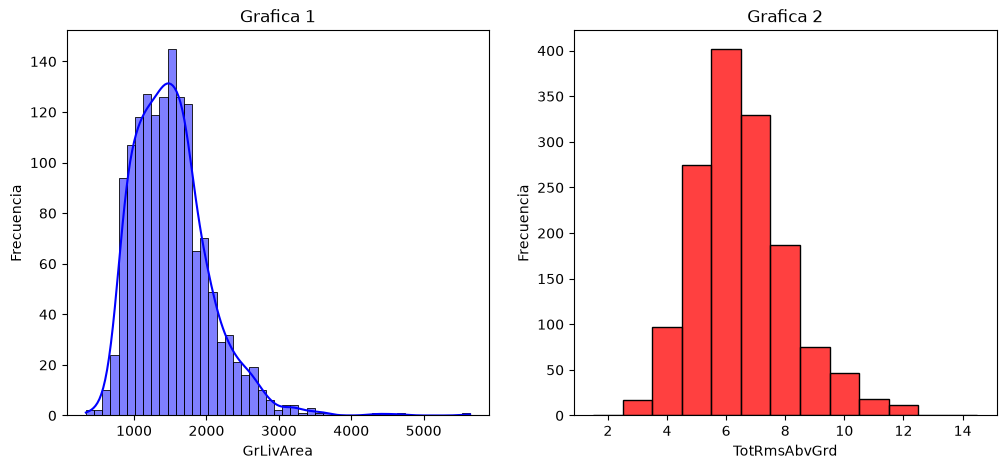

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(df['GrLivArea'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Grafica 1')
axes[0].set_xlabel('GrLivArea')
axes[0].set_ylabel('Frecuencia')
sns.histplot(df['TotRmsAbvGrd'], discrete=True, ax=axes[1], color='red')
axes[1].set_title('Grafica 2')
axes[1].set_xlabel('TotRmsAbvGrd')
axes[1].set_ylabel('Frecuencia')

plt.show()

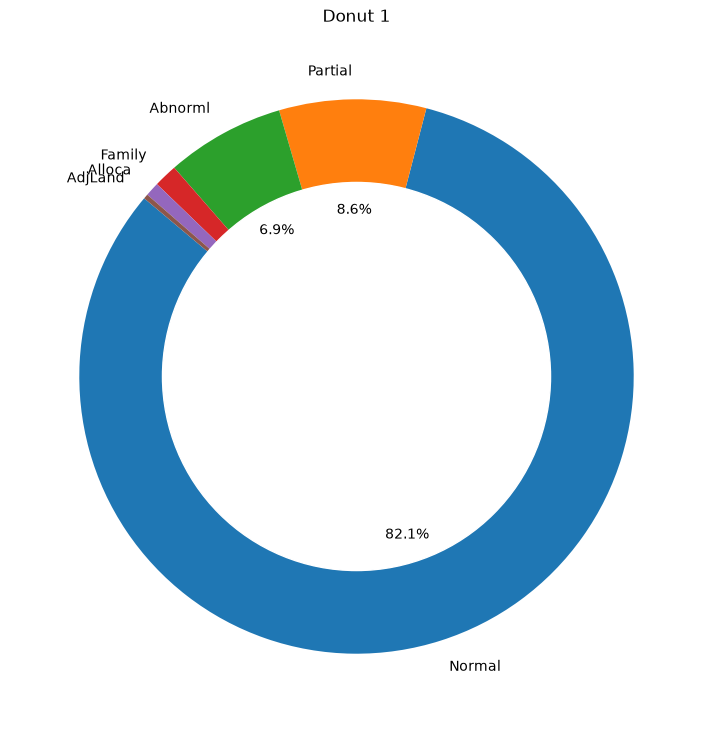

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

plt.figure(figsize=(9, 9))
sale_counts = df['SaleCondition'].value_counts()
plt.pie(sale_counts, labels=sale_counts.index, autopct=lambda p: f'{p:.1f}%' if p > 3 else '', startangle=140)
circle_neigh = plt.Circle((0, 0), 0.70, color='white')
p_neigh = plt.gcf()
p_neigh.gca().add_artist(circle_neigh)
plt.title('Donut 1')
plt.show()

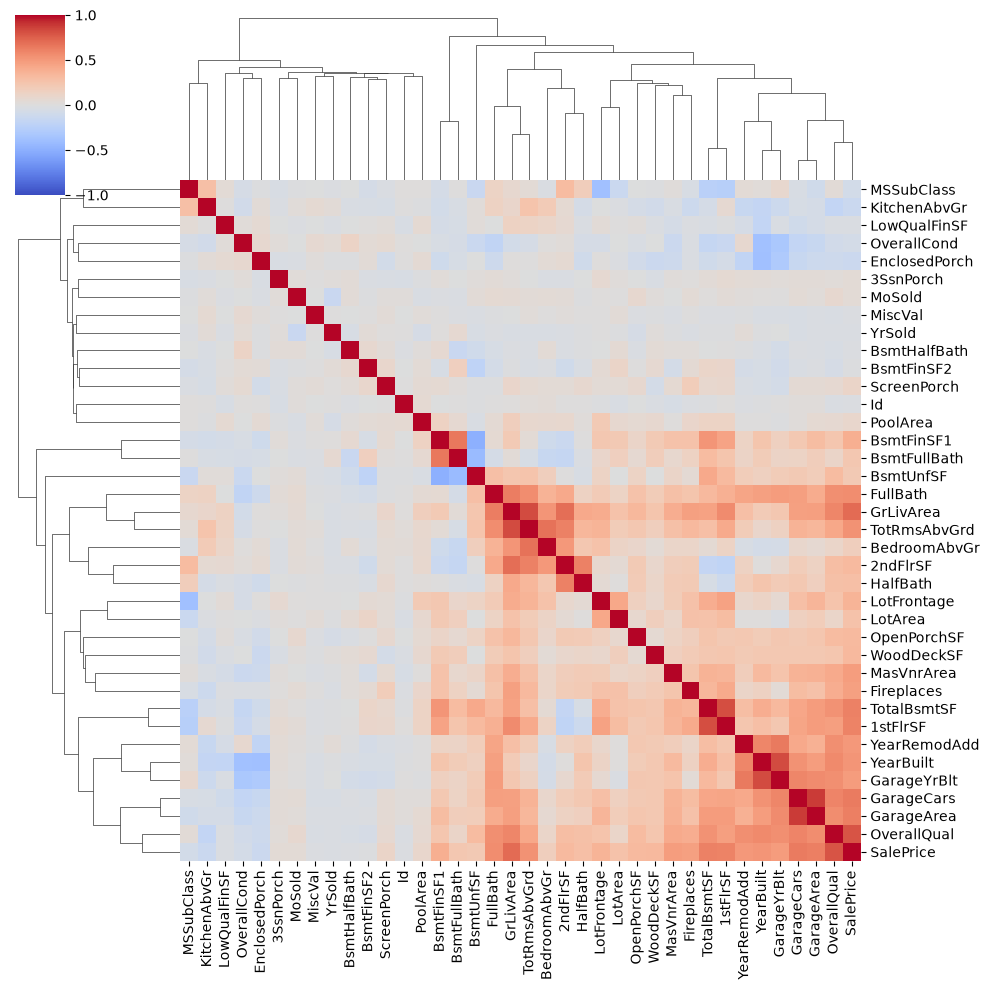

GrLivArea       1.000000
TotRmsAbvGrd    0.825489
SalePrice       0.708624
2ndFlrSF        0.687501
FullBath        0.630012
OverallQual     0.593007
Name: GrLivArea, dtype: float64


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df_num = df.select_dtypes(include=[np.number])
matriz_corr = df_num.corr()
sns.clustermap(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1, figsize=(10, 10))
plt.show()

corr_precio = matriz_corr['GrLivArea'].sort_values(ascending=False)
print(corr_precio.head(6))

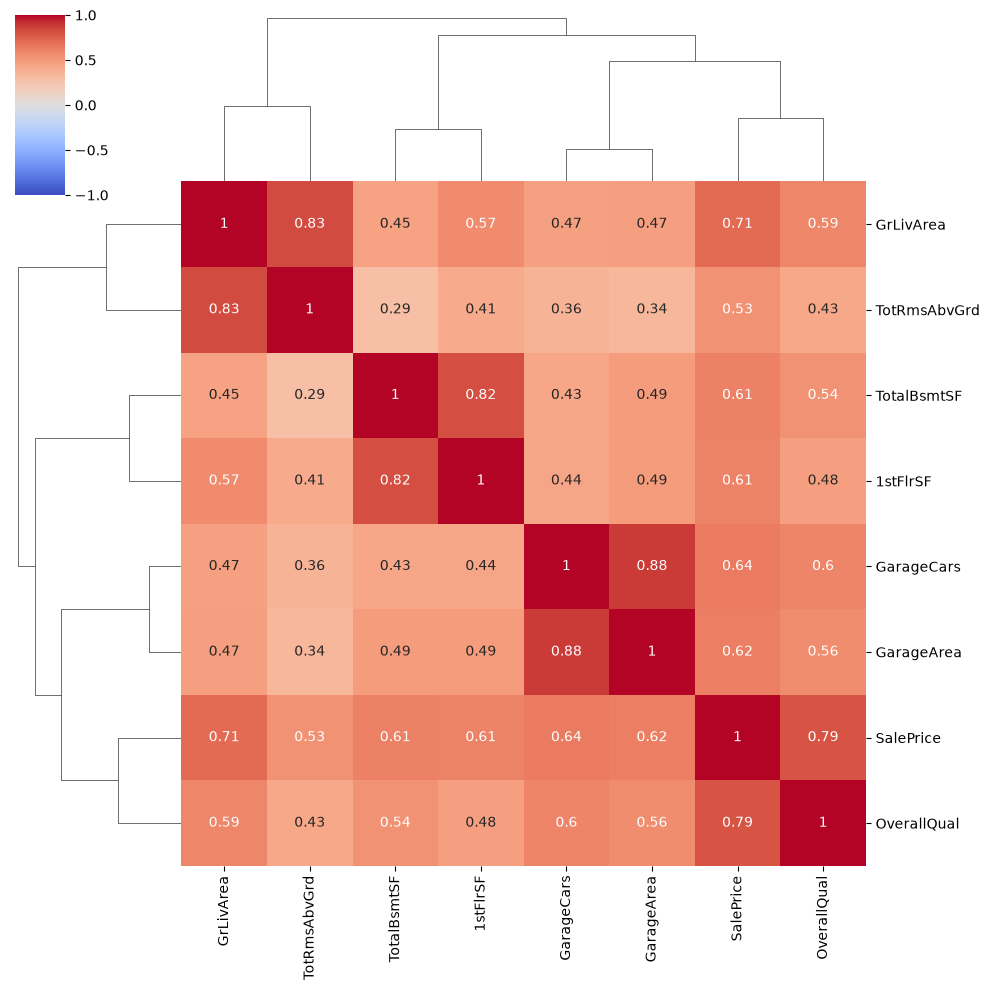

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

cols = ['SalePrice', 'OverallQual', 'GrLivArea', 'TotRmsAbvGrd', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF']

matriz_corr = df[cols].corr()
sns.clustermap(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1, figsize=(10, 10), annot=True)
plt.show()



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

print(df.shape[0])
print(df.shape[1])

print(df.dtypes.value_counts())

print(df['YearBuilt'].describe())
print(df['YearBuilt'].nunique())

1460
81
str        43
int64      35
float64     3
Name: count, dtype: int64
count    1460.000000
mean     1971.267808
std        30.202904
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2000.000000
max      2010.000000
Name: YearBuilt, dtype: float64
112


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df_new = df[(df['Neighborhood'] == 'NAmes') & (df['OverallQual'] >= 6) & (df['YearBuilt'] >= 1960)]
print(df_new.shape[0])

print(df_new['SalePrice'].mean())
print(df_new['SalePrice'].median())

57
177636.84210526315
167000.0


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

a = df.isnull().sum()
a = a[a > 0].sort_values(ascending = False)
print(a)

b = df['GarageArea'] == 0
c = df['GarageType'].isnull()

print(b.equals(c))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64
True


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df = df.drop(columns = ['Id', 'Utilities'], errors = 'ignore')

df['Alley'] = df['Alley'].fillna('None')
df['FireplaceQu'] = df['FireplaceQu'].fillna('None')

df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x : x.fillna(x.median()))

cols = ['Alley', 'FireplaceQu', 'Electrical', 'GarageYrBlt', 'LotFrontage']

print(df[cols].isnull().sum())


Alley          0
FireplaceQu    0
Electrical     0
GarageYrBlt    0
LotFrontage    0
dtype: int64


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df['KitchenQual_num'] = df['KitchenQual'].map({'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})
df['tiene_chimenea'] = np.where(df['Fireplaces'] > 0, 1, 0)

print(df['KitchenQual_num'].value_counts(dropna = False))
print(df['tiene_chimenea'].value_counts(normalize = True) * 100)

KitchenQual_num
3    735
4    586
5    100
2     39
Name: count, dtype: int64
tiene_chimenea
1    52.739726
0    47.260274
Name: proportion, dtype: float64


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df['Antiguedad_Venta'] = df['YrSold'] - df['YearBuilt']
df['Superficie_Total'] = df['TotalBsmtSF'] + df['GrLivArea']

df['LotArea_log'] = np.log1p(df['LotArea'])

df_copy = df.copy()
df_copy = pd.get_dummies(df_copy, columns = ['MSZoning', 'LotShape'], drop_first = True, dtype = int)

print(df.shape[1])
print(df_copy.shape[1])


84
89


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df.groupby('BldgType')['SalePrice'].agg(['count', 'mean', 'median']).sort_values(by = 'median', ascending = False)

,count,mean,median
BldgType,,,
TwnhsE,114,181959.342105,172200.0
1Fam,1220,185763.807377,167900.0
Twnhs,43,135911.627907,137500.0
Duplex,52,133541.076923,135980.0
2fmCon,31,128432.258065,127500.0


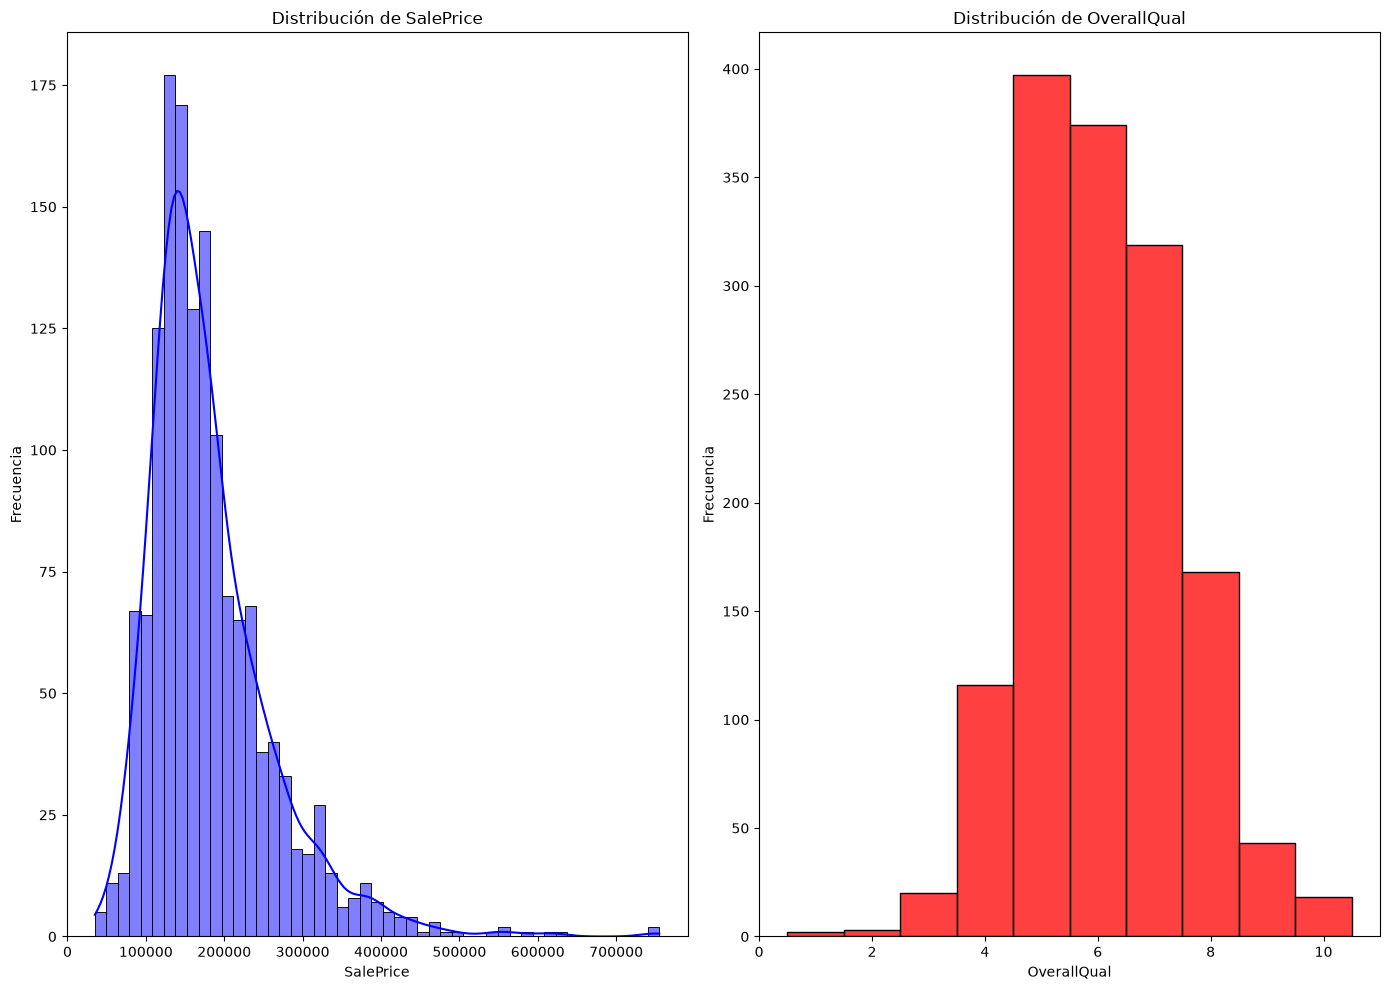

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 10))

sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribución de SalePrice')
axes[0].set_xlabel('SalePrice')
axes[0].set_ylabel('Frecuencia')

sns.histplot(df['OverallQual'], discrete=True, ax=axes[1], color='red')
axes[1].set_title('Distribución de OverallQual')
axes[1].set_xlabel('OverallQual')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

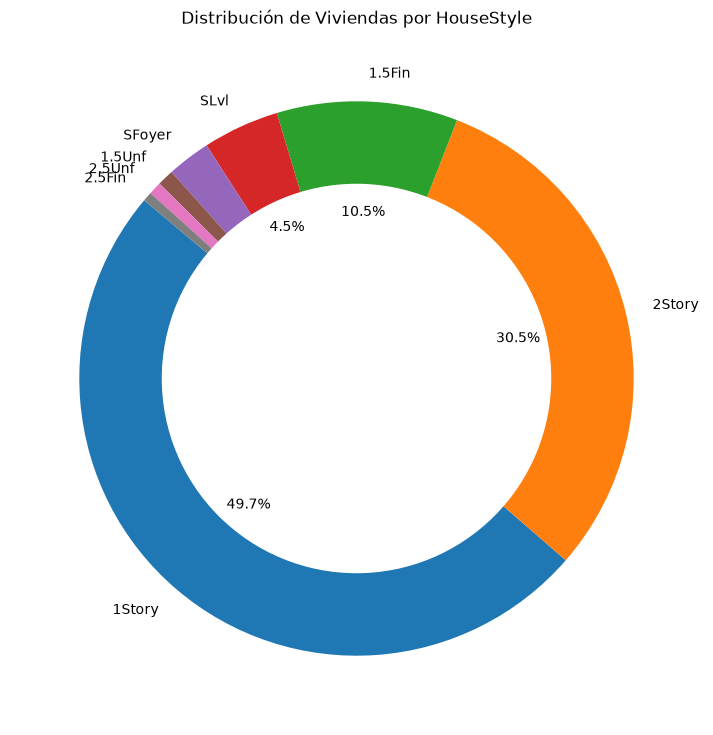

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

plt.figure(figsize=(9, 9))
house_counts = df['HouseStyle'].value_counts()
plt.pie(house_counts, labels = house_counts.index, 
        autopct=lambda p: f'{p:.1f}%' if p > 3 else '', startangle=140)
circle_neigh = plt.Circle((0, 0), 0.70, color='white')
p_neigh = plt.gcf()
p_neigh.gca().add_artist(circle_neigh)
plt.title('Distribución de Viviendas por HouseStyle')
plt.show()

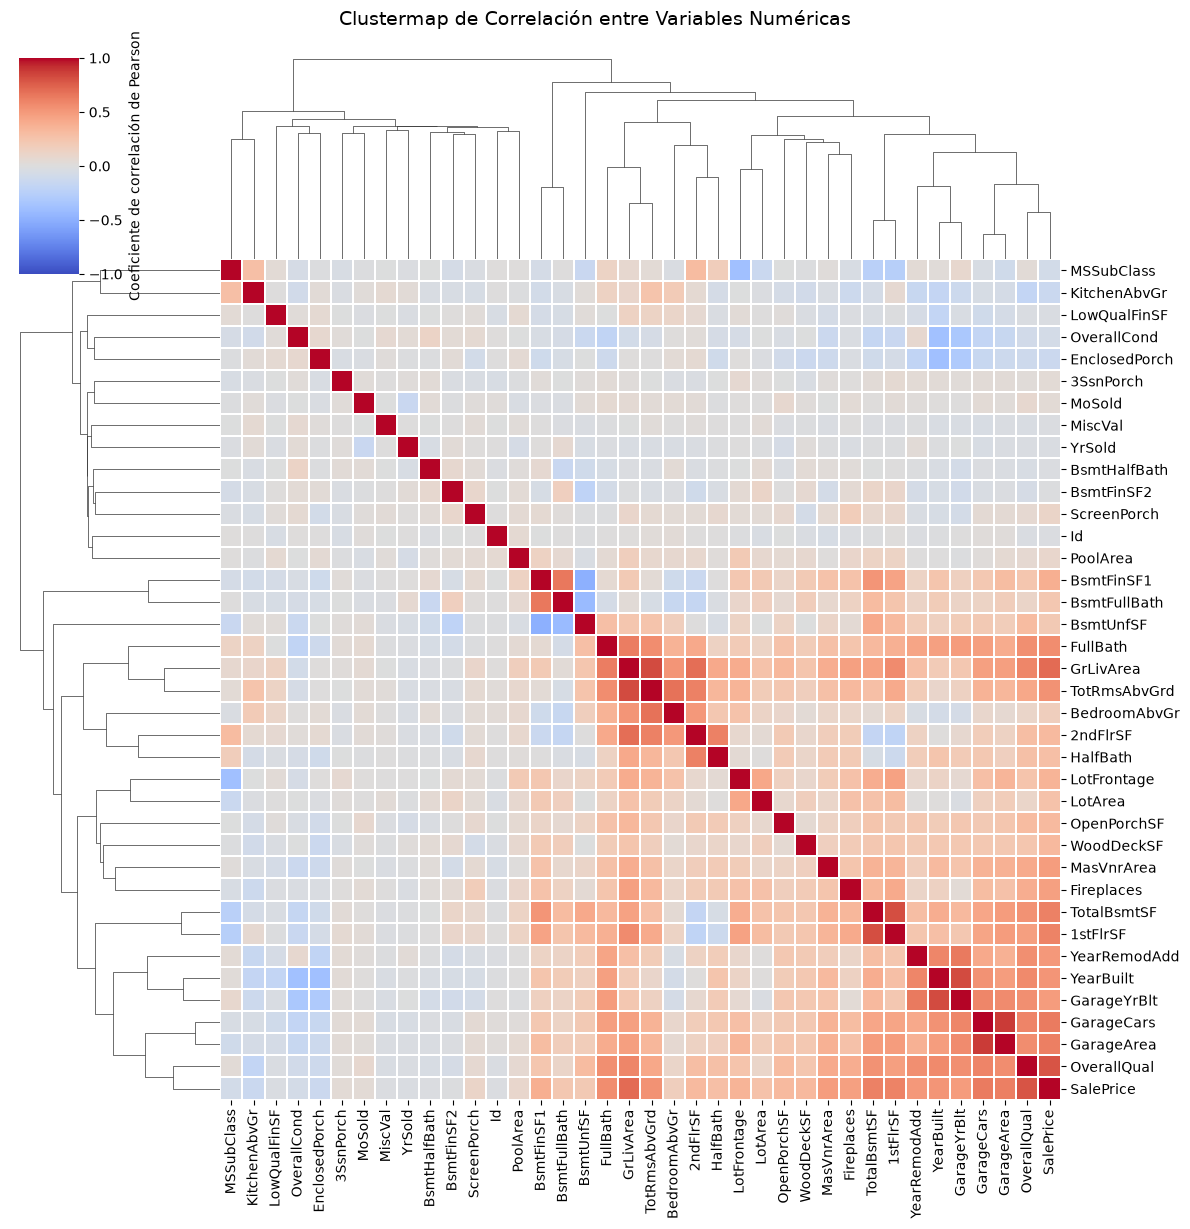

Top 5 variables con mayor correlación positiva con SalePrice:
SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
Name: SalePrice, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

df_numericas = df.select_dtypes(include=[np.number])
matriz_corr = df_numericas.corr()

cluster_plot = sns.clustermap(
    matriz_corr,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    figsize=(12, 12),
    linewidths=0.2,
    cbar_kws={'label': 'Coeficiente de correlación de Pearson'}
)
cluster_plot.fig.suptitle('Clustermap de Correlación entre Variables Numéricas', y=1.02, fontsize=14)
plt.show()

corr_precio = matriz_corr['SalePrice'].sort_values(ascending=False)
print("Top 5 variables con mayor correlación positiva con SalePrice:")
print(corr_precio.head(6))

In [ ]:
# ==============================================================================
#  CHULETA COMPLETA EXAMEN PRÁCTICA 2 - EDA Y PREPROCESAMIENTO (data.csv)
#  Todo está dentro de "if False:" para que no se ejecute ni rompa "Run All".
#  Copia el bloque que necesites en una celda nueva y adapta los nombres.
# ==============================================================================


    # ==========================================================================
    # 0. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN (SIEMPRE EN LA CELDA 1)
    # ==========================================================================
    import numpy as np                  # Cálculos matemáticos (log1p, where, number)
    import pandas as pd                 # Manejo de tablas (DataFrames)
    import matplotlib.pyplot as plt     # Gráficos base (subplots, pie, Circle, show)
    import seaborn as sns               # Gráficos estadísticos (histplot, clustermap)

    # Opcional: evitar que pandas recorte filas o columnas con "..." al imprimir
    pd.set_option('display.max_columns', None)
    pd.set_option('display.max_rows', None)

    # SI FALLA sns.clustermap POR FALTA DE SCIPY:
    # Ejecuta en una celda aparte ->  %pip install scipy
    # Después pulsa "Restart" (reiniciar kernel) y luego "Run All".


    # ==========================================================================
    # 1. CARGA, DIMENSIONES Y AUDITORÍA INICIAL DE VARIABLES
    # ==========================================================================
    df = pd.read_csv('data.csv')        # Carga el CSV en un DataFrame

    df.head()                           # Muestra las 5 primeras filas (df.head(10) para 10)
    df.tail()                           # Muestra las 5 últimas filas

    # Dimensiones: .shape devuelve tupla (filas, columnas) -> (1460, 81)
    n_filas = df.shape[0]               # Número de viviendas/instancias (equivale a len(df))
    n_cols  = df.shape[1]               # Número de variables/columnas
    print(f"Filas: {n_filas}, Columnas: {n_cols}")

    # Tipos de datos que infiere pandas (int64, float64, object)
    print(df.dtypes)                    # Tipo de cada columna (añadir .to_string() si se corta)
    print(df.dtypes.value_counts())     # Cuántas columnas hay de cada tipo

    # Inspección detallada de UNA columna concreta:
    df['Columna'].dtype                 # Tipo de dato de esa columna
    df['Columna'].nunique()             # Número de valores distintos (ignora NaN)
    df['Columna'].unique()              # Array con todos los valores distintos
    df['Columna'].describe()            # Resumen estadístico:
                                        #  - Numérica: count, mean, std, min, 25%, 50%(mediana), 75%, max
                                        #  - Texto (object): count, unique, top (moda), freq

    # Frecuencias de una columna categórica o discreta:
    df['Columna'].value_counts()                    # Conteo de cada categoría (mayor a menor)
    df['Columna'].value_counts(dropna=False)        # Igual, pero incluye cuántos NaN hay
    df['Columna'].value_counts(normalize=True)*100  # Porcentajes de 0 a 100%

    # Auditoría en bucle de una lista de columnas (resumen automático):
    cols_auditar = ['LotArea', 'LotFrontage', 'MSZoning', 'SalePrice']
    resumen = []
    for col in cols_auditar:
        es_num = pd.api.types.is_numeric_dtype(df[col])
        resumen.append({
            'Variable': col,
            'Tipo': str(df[col].dtype),
            'Nulos': df[col].isnull().sum(),
            'Unicos': df[col].nunique(),
            'Min': df[col].min() if es_num else 'N/A',
            'Max': df[col].max() if es_num else 'N/A'
        })
    df_resumen = pd.DataFrame(resumen)
    print(df_resumen)


    # ==========================================================================
    # 2. FILTRADO DE FILAS Y ESTADÍSTICOS BÁSICOS
    # ==========================================================================
    # Reglas:
    #  - Cada condición SIEMPRE entre paréntesis (...)
    #  - Y lógico: &   |   O lógico: |   |   Negación: ~
    #  - OJO EXAMEN: tras crear df_sub, calcula la media/mediana sobre df_sub, NO sobre df.

    df_sub = df[
        (df['Neighborhood'] == 'NAmes') &
        (df['OverallQual'] >= 6) &
        (df['YearBuilt'] >= 1960)
    ]

    # Filtrar si el valor está dentro de una lista de opciones:
    df_sub2 = df[df['Neighborhood'].isin(['NAmes', 'CollgCr', 'OldTown'])]

    print("Viviendas filtradas:", df_sub.shape[0])
    print("Media:",   df_sub['SalePrice'].mean())
    print("Mediana:", df_sub['SalePrice'].median())
    print("Mínimo:",  df_sub['SalePrice'].min())
    print("Máximo:",  df_sub['SalePrice'].max())
    print("Desv. típica:", df_sub['SalePrice'].std())
    print("Asimetría (skew):", df_sub['SalePrice'].skew())  # >0 cola derecha, ~0 simétrica


    # ==========================================================================
    # 3. AUDITORÍA DE NULOS (NaN) Y COMPROBACIÓN LÓGICA
    # ==========================================================================
    # Ver SOLO las columnas que tienen nulos (> 0), ordenadas de mayor a menor:
    nulos = df.isnull().sum()
    nulos = nulos[nulos > 0].sort_values(ascending=False)
    print(nulos)
    print("Total columnas con nulos:", len(nulos))

    # Porcentaje de nulos por columna:
    porcentaje_nulos = (df.isnull().mean() * 100)
    print(porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False))

    # Comprobar si dos condiciones coinciden en EXACTAMENTE las mismas filas:
    # TRAMPA: NUNCA usar "== None" ni "== np.nan". Siempre usar .isnull() o .isna().
    cond_area = (df['GarageArea'] == 0)
    cond_tipo = df['GarageType'].isnull()
    print("¿Coinciden exactamente?:", cond_area.equals(cond_tipo))  # Devuelve True o False

    # Tabla comparativa de nulos ANTES y DESPUÉS de limpiar (guarda nulos_orig al inicio):
    nulos_orig = df.isnull().sum()
    # ... (aquí iría tu limpieza sobre df) ...
    nulos_act = df.isnull().sum()
    cols_con_nulos = nulos_orig[nulos_orig > 0].index
    tabla_comparativa = pd.DataFrame({
        'Columna': cols_con_nulos,
        'Nulos_Antes': [nulos_orig[c] for c in cols_con_nulos],
        'Nulos_Despues': [nulos_act[c] if c in df.columns else 'Eliminada' for c in cols_con_nulos]
    })
    print(tabla_comparativa)


    # ==========================================================================
    # 4. LIMPIEZA: BORRADO DE COLUMNAS/FILAS E IMPUTACIÓN DE NULOS
    # ==========================================================================
    # 4.1 Borrar columnas irrelevantes o casi constantes (Id, Utilities, etc.):
    # TRAMPA: Reasignar siempre "df = df.drop(...)" para que se guarde el cambio.
    # errors='ignore' evita que falle si ejecutas la celda dos veces seguidas.
    df = df.drop(columns=['Id', 'Utilities'], errors='ignore')

    # 4.2 Borrar filas con nulos en columnas concretas (si lo piden explícitamente):
    df = df.dropna(subset=['Columna_A', 'Columna_B'])

    # 4.3 Imputar nulos estructurales en categóricas (ausencia del elemento -> 'None'):
    # TRAMPA: 'None' va ENTRE COMILLAS (texto), no el None vacío de Python.
    df['Alley'] = df['Alley'].fillna('None')

    # Imputar varias columnas categóricas a la vez con bucle:
    for col in ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'FireplaceQu']:
        df[col] = df[col].fillna('None')

    # 4.4 Imputar categórica por MODA (valor más frecuente, ej. Electrical):
    # TRAMPA: Poner siempre [0] al final porque .mode() devuelve una Series, no un texto.
    df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

    # 4.5 Imputar numérica con la mediana o media global:
    df['MasVnrArea'] = df['MasVnrArea'].fillna(df['MasVnrArea'].median())  # o .mean() o 0

    # 4.6 Imputar numérica copiando el valor de OTRA columna de la misma fila:
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

    # 4.7 Imputar numérica por GRUPOS (ej. mediana de LotFrontage según Neighborhood):
    # groupby agrupa, transform devuelve una Serie del mismo tamaño que df para rellenar fila a fila.
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(
        lambda x: x.fillna(x.median())
    )

    # 4.8 Verificación rápida tras limpiar (debe dar todo 0 y mantener filas):
    cols_check = ['Alley', 'Electrical', 'GarageYrBlt', 'LotFrontage']
    print(df[cols_check].isnull().sum())
    print("Viviendas restantes:", df.shape[0])


    # ==========================================================================
    # 5. INGENIERÍA DE VARIABLES (MAPEO, BINARIZACIÓN, LOGARITMO, DUMMIES)
    # ==========================================================================
    # 5.1 Recodificación ORDINAL (texto con orden -> números 1..5):
    escala_calidad = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
    df['KitchenQual_num'] = df['KitchenQual'].map(escala_calidad)
    # Comprobar que nada quedó sin mapear (no debería aparecer NaN):
    print(df['KitchenQual_num'].value_counts(dropna=False))

    # 5.2 Binarización con np.where(condicion, valor_si_True, valor_si_False):
    df['Tiene_Piscina'] = np.where(df['PoolArea'] > 0, 1, 0)
    df['Terreno_Con_Pendiente'] = np.where(df['LandSlope'] == 'Gtl', 0, 1)

    # 5.3 Variables derivadas (operaciones aritméticas entre columnas):
    df['Antiguedad_Venta'] = df['YrSold'] - df['YearBuilt']
    df['Superficie_Total'] = df['TotalBsmtSF'] + df['GrLivArea']

    # 5.4 Transformación logarítmica para reducir asimetría positiva / outliers:
    # np.log1p(x) calcula ln(1 + x) -> evita error (-infinito) cuando x == 0.
    df['LotArea_log'] = np.log1p(df['LotArea'])
    df['SalePrice_log'] = np.log1p(df['SalePrice'])

    # 5.5 Agrupar categorías minoritarias (< 3%) en 'Other' antes de codificar:
    frec = df['HouseStyle'].value_counts(normalize=True) * 100
    minoritarias = frec[frec < 3].index
    df['HouseStyle_agrup'] = df['HouseStyle'].replace(minoritarias, 'Other')

    # 5.6 One-Hot Encoding (para categóricas NOMINALES sin orden):
    # - df.copy() para no destruir el df original
    # - drop_first=True elimina la 1ª categoría de cada columna (evita multicolinealidad perfecta)
    # - dtype=int guarda 1 y 0 en vez de True y False
    df_cod = df.copy()
    df_cod = pd.get_dummies(
        df_cod,
        columns=['CentralAir', 'MSZoning', 'SaleCondition'],
        drop_first=True,
        dtype=int
    )
    print("Columnas antes:", df.shape[1], "| Columnas después:", df_cod.shape[1])


    # ==========================================================================
    # 6. AGRUPACIÓN Y RESÚMENES ESTADÍSTICOS (groupby + agg)
    # ==========================================================================
    # Calcular varias estadísticas de una columna numérica agrupando por una categórica:
    tabla_resumen = (
        df.groupby('BldgType')['SalePrice']
          .agg(['count', 'mean', 'median', 'min', 'max'])
          .sort_values(by='median', ascending=False)
    )
    print(tabla_resumen)

    # Variante: agregar distintas funciones a distintas columnas a la vez:
    tabla_multi = df.groupby('Neighborhood').agg(
        Num_Casas=('SalePrice', 'count'),
        Precio_Mediano=('SalePrice', 'median'),
        Area_Media=('GrLivArea', 'mean')
    ).sort_values(by='Precio_Mediano', ascending=False)
    print(tabla_multi.head(10))


    # ==========================================================================
    # 7. VISUALIZACIÓN: HISTOGRAMAS Y GRÁFICOS DE DONUT
    # ==========================================================================
    # 7.1 Histograma INDIVIDUAL:
    plt.figure(figsize=(8, 5))
    sns.histplot(df['SalePrice'], kde=True, color='skyblue')     # Continua -> kde=True
    # sns.histplot(df['OverallQual'], discrete=True, color='plum') # Discreta -> discrete=True
    plt.title('Distribución de SalePrice')
    plt.xlabel('SalePrice ($)')
    plt.ylabel('Frecuencia')
    plt.show()

    # 7.2 Panel de Histogramas 1 FILA x 2 COLUMNAS (índice simple: axes[0], axes[1]):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.histplot(df['GrLivArea'], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title('Distribución de GrLivArea')
    axes[0].set_xlabel('GrLivArea (sq ft)')
    axes[0].set_ylabel('Frecuencia')

    sns.histplot(df['TotRmsAbvGrd'], discrete=True, ax=axes[1], color='salmon')
    axes[1].set_title('Distribución de TotRmsAbvGrd')
    axes[1].set_xlabel('Habitaciones sobre rasante')
    axes[1].set_ylabel('Frecuencia')

    plt.tight_layout()   # Evita que se monten títulos y etiquetas
    plt.show()

    # 7.3 Panel de Histogramas 2 FILAS x 2 COLUMNAS (índice doble: axes[fila, col]):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    sns.histplot(df['LotFrontage'], kde=True,      ax=axes[0, 0])
    sns.histplot(df['LotArea'],     kde=True,      ax=axes[0, 1])
    sns.histplot(df['SalePrice'],   kde=True,      ax=axes[1, 0])
    sns.histplot(df['OverallQual'], discrete=True, ax=axes[1, 1])
    axes[0, 0].set_title('LotFrontage')
    axes[0, 1].set_title('LotArea')
    axes[1, 0].set_title('SalePrice')
    axes[1, 1].set_title('OverallQual')
    plt.tight_layout()
    plt.show()

    # 7.4 Gráfico de DONUT (para variables categóricas):
    counts = df['SaleCondition'].value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(
        counts,
        labels=counts.index,
        # Si hay POCAS categorías (3-4): usar autopct='%1.1f%%'
        # Si hay MUCHAS categorías (para no pisar textos): ocultar menores del 3%:
        autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
        startangle=140
    )
    # Añadir el círculo blanco central (convierte el pie en donut):
    circulo_blanco = plt.Circle((0, 0), 0.70, color='white')
    plt.gcf().gca().add_artist(circulo_blanco)
    plt.title('Distribución de SaleCondition')
    plt.show()


    # ==========================================================================
    # 8. CORRELACIONES Y CLUSTERMAP (MULTICOLINEALIDAD)
    # ==========================================================================
    # 8.1 Matriz de correlación sobre TODAS las numéricas (asegúrate de haber borrado 'Id'):
    df_num = df.drop(columns=['Id'], errors='ignore').select_dtypes(include=[np.number])

    matriz_pearson  = df_num.corr()                    # Lineal (por defecto: method='pearson')
    matriz_spearman = df_num.corr(method='spearman')   # No lineal / monótona (robusta a outliers)
    matriz_kendall  = df_num.corr(method='kendall')    # No lineal basada en concordancia de rangos

    # 8.2 Ranking Top 5 correlaciones con una variable (sin incluirse a sí misma):
    corr_obj = matriz_pearson['SalePrice'].sort_values(ascending=False)
    print("Top 5 positivas:\n", corr_obj.iloc[1:6])    # .iloc[1:6] salta el 1.0 de la propia variable
    print("Top 5 negativas:\n", corr_obj.tail(5))

    # 8.3 Clustermap COMPLETO (todas las numéricas):
    g = sns.clustermap(
        matriz_pearson,
        cmap='coolwarm',       # Rojo = positiva (+1), Azul = negativa (-1), Blanco = 0
        vmin=-1, vmax=1,       # Fija la escala siempre entre -1 y 1
        figsize=(12, 12),
        linewidths=0.2,
        cbar_kws={'label': 'Coeficiente de correlación de Pearson'}
    )
    g.fig.suptitle('Clustermap de Correlación entre Variables Numéricas', y=1.02)
    plt.show()

    # 8.4 Clustermap ENFOCADO en un subconjunto concreto (con números visibles dentro):
    cols_sub = [
        'SalePrice', 'OverallQual', 'GrLivArea', 'TotRmsAbvGrd',
        'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF'
    ]
    matriz_sub = df[cols_sub].corr()
    sns.clustermap(
        matriz_sub,
        cmap='coolwarm',
        vmin=-1, vmax=1,
        annot=True,            # Escribe el coeficiente dentro de cada celda
        fmt='.2f',             # Formato con 2 decimales (ej. 0.88)
        figsize=(8, 8)
    )
    plt.show()


    # ==========================================================================
    # 9. GUÍA RÁPIDA DE TEORÍA E INTERPRETACIÓN (PARA CELDAS MARKDOWN)
    # ==========================================================================
    """
    A) TIPOS DE VARIABLES:
       - Categóricas NOMINALES: sin orden lógico (ej. Neighborhood, Street, HouseStyle,
         MSZoning). ¡OJO! MSSubClass la lee pandas como int64, pero es NOMINAL real.
       - Categóricas ORDINALES: con jerarquía clara (ej. ExterQual, KitchenQual: Po<Fa<TA<Gd<Ex).
       - Numéricas DISCRETAS (conteos enteros: OverallQual, GarageCars, FullBath) vs
         CONTINUAS (mediciones: LotArea, GrLivArea, SalePrice).
       - Numéricas de INTERVALO (el 0 es arbitrario, solo comparas diferencias: YearBuilt, temperatura)
         vs de RAZÓN / RATIO (el 0 es ausencia real, puedes decir "el doble": SalePrice, LotArea).

    B) VALORES NULOS (NaN):
       - 3 opciones generales: BORRAR (filas o columnas), IMPUTAR (rellenar) o IGNORAR
         (peligro: ignorarlos provoca errores o sesgos en cálculos y modelos).
       - Nulos ESTRUCTURALES (Alley, FireplaceQu, PoolQC, Garage*, Bsmt*): según data-description,
         NA significa "la casa NO tiene ese elemento". Se imputan con 'None' (texto) o 0 (numérico).
         * Excepción GarageYrBlt: se imputa con YearBuilt (no con 0) para no distorsionar la escala temporal.
       - Nulos REALES / NO REGISTRADOS (LotFrontage, Electrical, MasVnrArea):
         * Categórica -> Moda (.mode()[0]).
         * Numérica -> Mediana (mejor por grupos, ej. mediana de LotFrontage por Neighborhood,
           porque parcelas del mismo barrio se parecen y la mediana es robusta frente a outliers).

    C) OUTLIERS Y ASIMETRÍA (HISTOGRAMAS):
       - No es trivial distinguir si un outlier es un error de registro o un dato extremo real.
       - 3 opciones ante outliers: usar MÉTODOS ROBUSTOS (mediana, log1p), ELIMINAR o REEMPLAZAR.
         Siempre hay que DOCUMENTAR la decisión tomada.
       - Si MEDIA > MEDIANA y el histograma tiene cola larga a la derecha -> ASIMETRÍA POSITIVA
         (ej. SalePrice, LotArea, GrLivArea).
         * Solución: aplicar transformación logarítmica np.log1p() para comprimir extremos y
           acercar la distribución a la normalidad (clave para regresión lineal).
         * Si la distribución ya es simétrica/acampanada (ej. OverallQual), NO necesita log1p.

    D) DECISIONES SOBRE CATEGÓRICAS (DONUT Y CODIFICACIÓN):
       - Variable sin varianza o casi constante (ej. Utilities 99.9% AllPub, Street 99.6% Pave,
         LandSlope 94.7% Gtl): aporta poca información -> ELIMINAR o BINARIZAR (0 = mayoría, 1 = resto).
       - Variable nominal importante (ej. Neighborhood, HouseStyle, SaleCondition): MANTENER y
         codificar con One-Hot Encoding (pd.get_dummies con drop_first=True para evitar
         multicolinealidad perfecta). Si tiene muchas categorías pequeñas (< 3%), agruparlas antes en 'Other'.
       - Variable ordinal (ej. KitchenQual, ExterQual): mapear a enteros respetando el orden (1..5).

    E) CORRELACIONES, CLUSTERMAP Y MULTICOLINEALIDAD:
       - Clustermap vs Heatmap: clustermap hace agrupamiento jerárquico (dendrograma) y junta
         automáticamente variables muy correlacionadas (facilita detectar redundancias).
       - Pearson (.corr()) mide relación LINEAL y es sensible a outliers.
       - Spearman / Kendall miden relaciones NO LINEALES / monótonas y son robustos a outliers.
       - REGLA DE ORO: CORRELACIÓN NO IMPLICA CAUSALIDAD (indica asociación estadística, no causa-efecto).
         Además, correlación Pearson ~ 0 no descarta relaciones no lineales.
       - Parejas REDUNDANTES típicas en data.csv (ramas cortas en el dendrograma):
           * GarageCars y GarageArea (r = 0.88) -> quedarse con GarageCars (mayor r con SalePrice)
           * YearBuilt y GarageYrBlt (r = 0.85) -> quedarse con YearBuilt
           * GrLivArea y TotRmsAbvGrd (r = 0.83) -> quedarse con GrLivArea
           * TotalBsmtSF y 1stFlrSF (r = 0.82) -> quedarse con TotalBsmtSF
         Meter ambas variables redundantes en una regresión lineal provoca MULTICOLINEALIDAD
         (duplica información e inestabiliza los coeficientes del modelo).
    """


    # ==========================================================================
    # 10. CHECKLIST ANTI-ERRORES EN EL EXAMEN
    # ==========================================================================
    # [ ] ¿Reasignaste df = df.drop(..., errors='ignore')?
    # [ ] ¿Usaste .isnull() en vez de "== None"?
    # [ ] ¿Pusiste [0] al usar .mode()[0]?
    # [ ] ¿Pusiste 'None' entre comillas en fillna('None')?
    # [ ] ¿Usaste df_filtrado (y no df) al calcular media/mediana tras filtrar?
    # [ ] ¿Pusiste normalize=True antes de multiplicar por 100 en value_counts?
    # [ ] ¿Borraste 'Id' antes de hacer el clustermap y usaste .iloc[1:6] para el Top 5?
    # [ ] ¿Pusiste plt.tight_layout() antes de plt.show() y títulos descriptivos?

    
    # ==============================================================================
#  BLOQUE EXTRA: CÓMO TOMAR DECISIONES AL MODIFICAR DATOS (NULOS, OUTLIERS, COLS)
#  Pégalo dentro de tu "if False:" o déjalo en una celda aparte con "if False:".
# ==============================================================================


    # ==========================================================================
    # 11. CÓDIGO PARA DETECTAR Y TRATAR OUTLIERS (VALORES ATÍPICOS)
    # ==========================================================================
    col = 'LotArea'   # Cambia por la columna numérica que quieras analizar

    # 11.1 Detección visual rápida (Boxplot / Diagrama de caja)
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Detección de outliers en {col}')
    plt.show()

    # 11.2 Detección matemática por Regla del Rango Intercuartílico (IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"Límites IQR de {col}: [{lim_inf:.2f}, {lim_sup:.2f}]")
    print(f"Número de outliers detectados: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

    # 11.3 LAS 3 FORMAS DE ACTUAR EN CÓDIGO SOBRE OUTLIERS:
    # OPCIÓN A (Recomendada si son datos reales extremos): Método robusto / Logaritmo
    df[f'{col}_log'] = np.log1p(df[col])

    # OPCIÓN B (Reemplazar / Recortar topes o "Winsorizing" con .clip()):
    # Sustituye los valores fuera de rango por los límites superior/inferior sin borrar filas
    df[f'{col}_clip'] = df[col].clip(lower=lim_inf, upper=lim_sup)

    # OPCIÓN C (Eliminar filas con outliers — SOLO si son errores claros o casos imposibles):
    # OJO: Esto reduce df.shape[0]. Comprueba siempre cuántas filas quedan.
    df_sin_outliers = df[(df[col] >= lim_inf) & (df[col] <= lim_sup)]
    print("Filas antes:", len(df), "| Filas después:", len(df_sin_outliers))


    # ==========================================================================
    # 12. ÁRBOLES DE DECISIÓN: ¿QUÉ HAGO CON CADA PROBLEMA DE LOS DATOS?
    # ==========================================================================
    """
    ============================================================================
    DECISIÓN 1: ¿QUÉ HAGO CON LOS VALORES NULOS (NaN)?
    ============================================================================
    Opciones posibles: BORRAR, IMPUTAR (rellenar) o IGNORAR (evitar ignorar: da errores).

    PASO 1 -> Consulta `data-description.txt` (o el enunciado):
       ¿El NaN significa "la casa NO tiene ese elemento" (NULO ESTRUCTURAL)?
       (Ejemplos: Alley, PoolQC, Fence, FireplaceQu, Garage*, Bsmt*)
       |
       +--> SÍ (ausencia física real):
       |      * Si es CATEGÓRICA (texto)  --> Rellenar con 'None' (entre comillas).
       |      * Si es NUMÉRICA de tamaño  --> Rellenar con 0 (ej. superficie/plazas).
       |      * EXCEPCIÓN TEMPORAL (ej. GarageYrBlt): NO poner 0 (crearía un año 0
       |        artificial que rompe la escala). Imputar con otra columna lógica
       |        como `YearBuilt`.
       |
       +--> NO (dato REAL perdido / error de registro, ej. LotFrontage, Electrical):
              Mira qué porcentaje de la columna es nulo:
              * Muy alto (> 50-70% de datos perdidos reales y poca relevancia)
                --> BORRAR LA COLUMNA (`df = df.drop(columns=[...])`).
              * Bajo / Moderado (no queremos perder filas):
                - Si es CATEGÓRICA  --> Imputar con la MODA (`.mode()[0]`).
                - Si es NUMÉRICA sin outliers/simétrica --> Imputar con la MEDIA.
                - Si es NUMÉRICA con outliers/asimétrica --> Imputar con la MEDIANA.
                - Si es NUMÉRICA que depende mucho de un grupo (ej. LotFrontage
                  depende del barrio `Neighborhood`) --> MEDIANA POR GRUPOS
                  (`groupby(...).transform(lambda x: x.fillna(x.median()))`).
              * Caso residual (1 o 2 filas con casi todo vacío) --> Solo aquí
                valorar borrar filas (`dropna(subset=[...])`), justificando que
                la pérdida de muestras es despreciable.

    ============================================================================
    DECISIÓN 2: ¿QUÉ HAGO CON LOS VALORES ATÍPICOS (OUTLIERS)?
    ============================================================================
    Regla clave: NO es trivial saber si un outlier es un ERROR o un DATO EXTREMO REAL.
    Analiza siempre el contexto (min, max, histograma/boxplot y sentido físico):

    CASO A -> ES UN ERROR EVIDENTE O DATO IMPOSIBLE
              (Ej: superficie negativa, año de construcción 2500, precio 0 $)
              * Acción: ELIMINAR la fila o REEMPLAZAR el valor (pasarlo a NaN e imputarlo).

    CASO B -> ES UN DATO EXTREMO PERO REAL (Ej: mansión de 755.000 $ o finca de 215.000 sq ft)
              * Acción 1 (PREFERIDA): NO borrar la fila (perderías información real del
                mercado). Usar MÉTODOS ROBUSTOS:
                - Estadísticos robustos: Mediana en vez de media; Spearman en vez de Pearson.
                - Transformación de escala: `np.log1p()` para comprimir la cola derecha
                  y reducir la asimetría antes de entrenar modelos lineales.
              * Acción 2 (Alternativa): REEMPLAZAR / RECORTAR extremos con `.clip()` a un
                límite razonable (ej. percentil 99 o límite IQR) si distorsionan mucho.
              * Acción 3 (Último recurso): ELIMINAR solo los 1-2 registros aislados que
                rompan la relación global (ej. casa enorme vendida a precio ridículo).

    OBLIGATORIO EN TODOS LOS CASOS: Documentar siempre la decisión tomada en Markdown
    e indicar cuántas filas se conservan o se han eliminado.

    ============================================================================
    DECISIÓN 3: ¿MANTENGO, ELIMINO O TRANSFORMO UNA COLUMNA?
    ============================================================================
    1. ¿Es un identificador sin significado físico (ej. `Id`)?
       --> ELIMINAR SIEMPRE (riesgo de sobreajuste al orden de las filas).

    2. ¿Tiene varianza casi cero (casi todas las filas tienen el mismo valor)?
       * > 99% igual (ej. `Utilities`: 99.9% AllPub, `Street`: 99.6% Pave)
         --> ELIMINAR (no distingue unas casas de otras).
       * 90% - 95% igual (ej. `LandSlope`: 94.7% Gtl)
         --> ELIMINAR (modelos simples) o BINARIZAR (`0` = mayoría, `1` = resto).

    3. ¿Es categórica? ¿Cómo la paso a números?
       * Tiene ORDEN lógico (ej. `ExterQual`, `KitchenQual`, `LotShape`, `LandSlope`)
         --> MAPEO ORDINAL a enteros respetando jerarquía (`.map({'Po':1, ..., 'Ex':5})`).
       * NO tiene orden (ej. `Neighborhood`, `MSZoning`, `HouseStyle`, `MSSubClass`)
         --> ONE-HOT ENCODING (`pd.get_dummies(..., drop_first=True, dtype=int)`).
         * Truco: Si tiene muchas categorías minúsculas (< 3%), agrúpalas antes
           en `'Other'` para no disparar el número de columnas vacías.
       * ¡OJO! Si `pandas` la leyó como número pero es código sin orden (`MSSubClass`),
         trátala como CATEGÓRICA NOMINAL, nunca como numérica.

    4. ¿Hay dos variables numéricas casi idénticas (correlación |r| > 0.80 en clustermap)?
       (Ej: `GarageCars` vs `GarageArea`, `TotalBsmtSF` vs `1stFlrSF`, `GrLivArea` vs `TotRmsAbvGrd`)
       --> Riesgo de MULTICOLINEALIDAD en regresión lineal.
       --> QUEDARSE SOLO CON UNA de cada pareja: elige la que tenga MAYOR correlación
           con la variable objetivo (`SalePrice`), menos nulos o interpretación más directa.

    5. ¿Son fechas / años (`YearBuilt`, `YearRemodAdd`)?
       --> Son numéricas de INTERVALO (el año 0 es arbitrario). Para modelar suele ser
           mejor crear una variable derivada de ANTIGÜEDAD (`YrSold - YearBuilt`).

    ============================================================================
    PLANTILLA DE JUSTIFICACIÓN PERFECTA PARA EL EXAMEN (3 LÍNEAS EN MARKDOWN)
    ============================================================================
    1. QUÉ OBSERVO: "La variable X presenta [259 nulos / asimetría positiva / 95% en Gtl / r=0.88 con Y]."
    2. QUÉ DECIDO Y POR QUÉ: "Como [es un dato real no registrado / son valores extremos reales /
       aporta poca varianza / genera multicolinealidad], decido [imputar con la mediana por barrio /
       aplicar log1p / binarizar / eliminar Y y conservar X por mayor correlación con SalePrice]."
    3. COMPROBACIÓN: "Tras aplicar el cambio, los nulos pasan a 0 y se mantienen las 1460 filas."
    """